# 05 · Evaluación final

**Fase 5 de CRISP-DM.** Los modelos se eligieron con `val` (notebooks 04). Aquí se miden en `test` (Kaggle) y `test_propias`
(46 fotos nuestras) **sin reentrenar, sin mover umbrales y sin cambiar de modelo**: si un resultado contradice la elección
hecha en `val`, se reporta y se discute, pero la elección no cambia.

Métrica principal: **macro-F1**. Dos precauciones que condicionan todo el análisis:

- **Pocas *regular***: 32 en `val`, 32 en `test`, 15 en `test_propias`. Por eso se reportan intervalos.
- **La proporción de clases cambia**: *regular* es 3,7 % en `test` y 32,6 % en `test_propias`. La precisión (y por tanto el
  macro-F1) depende de esa proporción, así que el macro-F1 crudo de ambos conjuntos **no es comparable**. Se añade el
  macro-F1 con **clases equiprobables** (`macro_f1_prevalencia`), que solo depende de los aciertos por clase.

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score, recall_score

from src.config import CHECKPOINTS_DIR, DATA_DIR, FRUITS, QUALITY_CLASSES, RESULTS_DIR, SIZE_CLASSES
from src.data.carga import cargar_imagen, cargar_mascara, cargar_splits
from src.data.segmentacion import aplicar_mascara, segmentar_fruta
from src.data.tensores import cargar_tensores
from src.evaluation.metricas import (bootstrap_diferencia, intervalo_bootstrap, macro_f1_prevalencia, resumen, tabla)
from src.evaluation.prediccion import ModeloCNN, ModeloSVM
from src.features.extraccion import NOMBRES, extraer
from src.models.clasicos import lineas_base
from src.training.entrenar_cnn import PRINCIPAL, resultado

FIG_DIR = ROOT / "docs" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "svg.fonttype": "none"})
pd.set_option("display.width", 200, "display.max_columns", 30)
SP = ["val", "test", "test_propias"]
D = {s: cargar_splits(s) for s in SP}
Y = {s: D[s].y.values for s in SP}
F1 = lambda a, b: f1_score(a, b, labels=[0, 1, 2], average="macro", zero_division=0)
REC = lambda a, b: recall_score(a, b, labels=[1], average="macro", zero_division=0)
F1EQ = macro_f1_prevalencia
print({s: D[s].quality.value_counts().reindex(QUALITY_CLASSES).to_dict() for s in SP})
print("Tomas (grupos):", {s: D[s].grupo.nunique() for s in SP}, "| CNN principal:", PRINCIPAL)

{'val': {'good': 440, 'regular': 32, 'bad': 445}, 'test': {'good': 424, 'regular': 32, 'bad': 402}, 'test_propias': {'good': 15, 'regular': 15, 'bad': 16}}
Tomas (grupos): {'val': 351, 'test': 360, 'test_propias': 45} | CNN principal: filtros_x2


## 1. Modelos y predicciones

Líneas base (ajustadas con `train`), SVM (`predict`, no el máximo de `predict_proba`) y CNN `filtros_x2` (semilla 42; la 43 se
reporta como variabilidad). Las variantes *imagen completa* y *sin aumento* solo se usan en las secciones 5 y 6.

In [2]:
def cargar_X(nombre, d):
    return pd.read_csv(DATA_DIR / f"features_{nombre}.csv").set_index("filename").loc[d.filename, NOMBRES].values.astype(np.float32)

pred, prob = {}, {}
tr = cargar_splits("train")
for n, m in lineas_base().items():
    m.fit(np.zeros((len(tr), 1)), tr.y.values)
    pred[n] = {s: m.predict(np.zeros((len(D[s]), 1))) for s in SP}

svm = joblib.load(CHECKPOINTS_DIR / "ml_mejor.joblib")
svm_c = joblib.load(CHECKPOINTS_DIR / "ml_mejor_imagen_completa.joblib")
pred["SVM"] = {s: svm.predict(cargar_X("fruta", D[s])) for s in SP}
prob["SVM"] = {s: svm.predict_proba(cargar_X("fruta", D[s])) for s in SP}
pred["SVM completa"] = {s: svm_c.predict(cargar_X("completa", D[s])) for s in SP}

X = {(s, e): cargar_tensores(D[s], e)[0] for s in SP for e in (True, False)}
CNNS = {"CNN": PRINCIPAL, "CNN (s43)": f"{PRINCIPAL}_s43", "CNN completa": f"{PRINCIPAL}_completa_s42",
        "CNN sin aumento": "sin_aumento", "CNN sin aumento (s43)": "sin_aumento_s43",
        "CNN sin aumento completa": "sin_aumento_completa_s42"}
for n, a in CNNS.items():
    m = ModeloCNN(a); pred[n], prob[n] = {}, {}
    for s in SP:
        pred[n][s], prob[n][s] = m.predecir_lote(X[s, m.cfg["enmascarar"]])

# Comprobación: en val se reproducen los números de los notebooks 04
v = pd.read_csv(RESULTS_DIR / "comparacion_val.csv", index_col=0)["macro-F1"]
REF = {"Dummy (clase mayoritaria)": v["Dummy (clase mayoritaria)"], "Dummy (aleatorio estratificado)": v["Dummy (aleatorio estratificado)"],
       "SVM": v["SVM (RBF)"], "CNN": v[f"CNN ({PRINCIPAL})"], "CNN (s43)": resultado(f"{PRINCIPAL}_s43")["val"]["macro-F1"]}
for n, r in REF.items():
    assert abs(F1(Y["val"], pred[n]["val"]) - r) < 2e-3, (n, F1(Y["val"], pred[n]["val"]), r)
# Comprobación: el módulo de predicción (para la app) coincide con las tablas precalculadas
ms, mc = ModeloSVM(), ModeloCNN()
ok = [(ms.predecir(np.array(cargar_imagen(f)), cargar_mascara(f))[0] == pred["SVM"]["test_propias"][i],
       mc.predecir(np.array(cargar_imagen(f)), cargar_mascara(f))[0] == pred["CNN"]["test_propias"][i])
      for i, (_, f) in enumerate(D["test_propias"].iterrows())]
print("val reproducido; coincidencia módulo vs tablas (SVM, CNN):", np.mean(ok, axis=0))

val reproducido; coincidencia módulo vs tablas (SVM, CNN): [1. 1.]


## 2. Tabla principal

In [3]:
PRINC = ["Dummy (clase mayoritaria)", "Dummy (aleatorio estratificado)", "SVM", "CNN", "CNN (s43)"]
filas = []
for n in PRINC:
    for s in SP:
        r = resumen(Y[s], pred[n][s]); f = {"modelo": n, "split": s, "n": len(Y[s])}
        f |= {k: r[k] for k in ["macro-F1", "acc. balanceada", "kappa", "accuracy"]}
        f["macro-F1 equiprob."] = F1EQ(Y[s], pred[n][s])
        f |= {f"{m} {c}": r[f"{m} {c}"] for c in QUALITY_CLASSES for m in ("F1", "recall")}
        f["precisión regular"] = r["precisión regular"]
        f["macro-F1 IC inf"], f["macro-F1 IC sup"] = intervalo_bootstrap(Y[s], pred[n][s], F1)
        f["recall regular IC inf"], f["recall regular IC sup"] = intervalo_bootstrap(Y[s], pred[n][s], REC)
        filas.append(f)
final = pd.DataFrame(filas); final.round(4).to_csv(RESULTS_DIR / "evaluacion_final.csv", index=False)
vista = final.pivot(index="modelo", columns="split")[["macro-F1", "acc. balanceada", "kappa", "macro-F1 equiprob."]]
vista = vista.reindex(PRINC).reindex(columns=SP, level=1).round(3); vista

macro-F1                     acc. balanceada                      kappa                     macro-F1 equiprob.                    
split                                val   test test_propias             val   test test_propias    val   test test_propias                val   test test_propias
modelo                                                                                                                                                            
Dummy (clase mayoritaria)          0.216  0.220        0.164           0.333  0.333        0.333  0.000  0.000        0.000              0.167  0.167        0.167
Dummy (aleatorio estratificado)    0.311  0.332        0.352           0.311  0.331        0.431 -0.058 -0.027        0.149              0.265  0.293        0.350
SVM                                0.727  0.723        0.470           0.780  0.769        0.539  0.802  0.796        0.314              0.769  0.758        0.468
CNN                                0.649  0.647        0.382           0.746  0.689        0.426  0.659  0.695        0.149              0.742  0.667        0.379
CNN (s43)                          0.668  0.666        0.393           0.799  0.718        0.428  0.675  0.716        0.149              0.800  0.700        0.390

In [4]:
cols = [f"{m} {c}" for m in ("F1", "recall") for c in QUALITY_CLASSES] + ["precisión regular"]
final[final.modelo.isin(["SVM", "CNN", "CNN (s43)"])].set_index(["modelo", "split"])[cols].round(3)

F1 good  F1 regular  F1 bad  recall good  recall regular  recall bad  precisión regular
modelo    split                                                                                                
SVM       val             0.903       0.333   0.944        0.866           0.531       0.942              0.243
          test            0.892       0.327   0.950        0.861           0.500       0.945              0.242
          test_propias    0.585       0.118   0.706        0.800           0.067       0.750              0.500
CNN       val             0.820       0.231   0.894        0.720           0.625       0.892              0.142
          test            0.839       0.188   0.913        0.750           0.375       0.943              0.125
          test_propias    0.424       0.000   0.722        0.467           0.000       0.812              0.000
CNN (s43) val             0.827       0.276   0.901        0.720           0.781       0.897              0.168
          test            0.839       0.230   0.928        0.750           0.438       0.965              0.156
          test_propias    0.424       0.087   0.667        0.467           0.067       0.750              0.125

In [5]:
# ¿Cuánto da el azar en las fotos propias? (2.000 simulaciones)
rng = np.random.default_rng(0); y = Y["test_propias"]; p = np.bincount(tr.y) / len(tr)
for nm, q in (("proporciones de train", p), ("uniforme", None)):
    v_ = [F1(y, rng.choice(3, len(y), p=q)) for _ in range(2000)]
    print(f"azar ({nm}): macro-F1 medio {np.mean(v_):.3f}, rango 95 % [{np.percentile(v_, 2.5):.3f}, {np.percentile(v_, 97.5):.3f}]")

azar (proporciones de train): macro-F1 medio 0.285, rango 95 % [0.186, 0.399]


azar (uniforme): macro-F1 medio 0.329, rango 95 % [0.196, 0.472]


**Lectura.**

- **En Kaggle los modelos generalizan**: `test` repite `val` (SVM 0,723 frente a 0,727; CNN 0,647 frente a 0,649). No hay señal de
  haber sobreajustado `val` al elegir. La excepción es el recall de *regular* de la CNN, que baja de 0,625 a 0,375 (20 a 12 de 32).
- **En las fotos propias caen mucho**: SVM 0,470 y CNN 0,382. Predecir al azar da de media 0,28–0,33 y, por suerte, hasta
  0,40 (proporciones de train) o 0,47 (uniforme): **la CNN no se distingue del azar** y el SVM supera el primero, pero queda en el límite del segundo.
- **No se cumplen las metas de la fase 1** (macro-F1 ≥ 0,85 en Kaggle y ≥ 0,70 en fotos propias) con ningún modelo.
- **Con la proporción de clases corregida la caída es igual o mayor** (SVM 0,758 → 0,468), así que no es un efecto de la mezcla.

## 3. Intervalos del 95 % y comparación SVM–CNN

Los intervalos individuales dicen cuánto se sabe de cada modelo; para decidir si **difieren** se usa el bootstrap *pareado*
(misma remuestra para ambos), porque dos intervalos pueden solaparse y aun así diferir. En `test` se añade el bootstrap por
**tomas** (columna `grupo`): las fotos de una misma toma no son independientes y remuestrear imágenes da intervalos optimistas.

In [6]:
ic = final[final.modelo.isin(["SVM", "CNN", "CNN (s43)"]) & (final.split != "val")]
txt = lambda a, b, c: f"{a:.3f} [{b:.3f}, {c:.3f}]"
display(pd.DataFrame({"modelo": ic.modelo, "split": ic.split,
    "macro-F1": [txt(*t) for t in ic[["macro-F1", "macro-F1 IC inf", "macro-F1 IC sup"]].values],
    "recall regular": [txt(*t) for t in ic[["recall regular", "recall regular IC inf", "recall regular IC sup"]].values]}))
filas = []
for s in ("test", "test_propias"):
    for b in ("CNN", "CNN (s43)"):
        for nm, me in (("macro-F1", F1), ("recall regular", REC)):
            for tipo, g in (("imágenes", None), ("tomas", D[s].grupo)):
                filas.append([s, f"SVM − {b}", nm, tipo, *bootstrap_diferencia(Y[s], pred["SVM"][s], pred[b][s], me, g)])
dif = pd.DataFrame(filas, columns=["split", "comparación", "métrica", "remuestreo", "diferencia", "IC inf", "IC sup"])
dif["¿0 fuera del IC?"] = (dif["IC inf"] > 0) | (dif["IC sup"] < 0)
dif.round(3)

,modelo,split,macro-F1,recall regular
7,SVM,test,"0.723 [0.677, 0.767]","0.500 [0.320, 0.667]"
8,SVM,test_propias,"0.470 [0.343, 0.582]","0.067 [0.000, 0.211]"
10,CNN,test,"0.647 [0.611, 0.681]","0.375 [0.206, 0.541]"
11,CNN,test_propias,"0.382 [0.285, 0.468]","0.000 [0.000, 0.000]"
13,CNN (s43),test,"0.666 [0.627, 0.703]","0.438 [0.261, 0.600]"
14,CNN (s43),test_propias,"0.393 [0.270, 0.499]","0.067 [0.000, 0.214]"


,split,comparación,métrica,remuestreo,diferencia,IC inf,IC sup,¿0 fuera del IC?
0,test,SVM − CNN,macro-F1,imágenes,0.076,0.028,0.122,True
1,test,SVM − CNN,macro-F1,tomas,0.076,0.016,0.134,True
2,test,SVM − CNN,recall regular,imágenes,0.125,-0.121,0.343,False
3,test,SVM − CNN,recall regular,tomas,0.125,-0.208,0.387,False
4,test,SVM − CNN (s43),macro-F1,imágenes,0.057,0.009,0.104,True
5,test,SVM − CNN (s43),macro-F1,tomas,0.057,-0.004,0.116,False
6,test,SVM − CNN (s43),recall regular,imágenes,0.062,-0.167,0.281,False
7,test,SVM − CNN (s43),recall regular,tomas,0.062,-0.300,0.350,False
8,test_propias,SVM − CNN,macro-F1,imágenes,0.087,-0.045,0.222,False
9,test_propias,SVM − CNN,macro-F1,tomas,0.087,-0.044,0.222,False


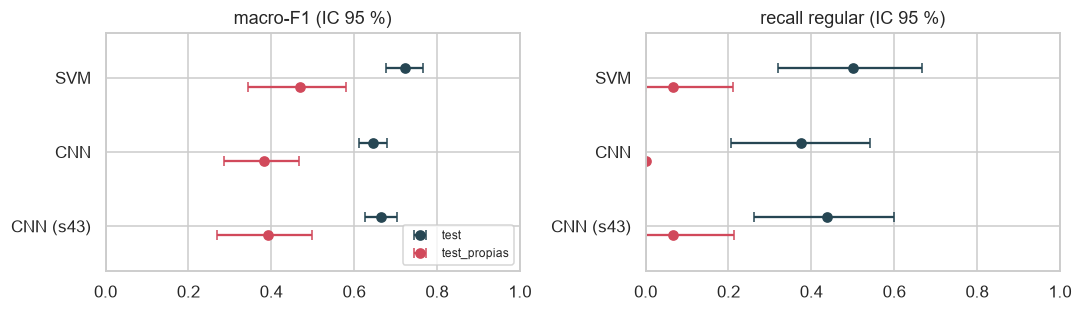

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=True)
for ax, (nm, lo) in zip(axes, (("macro-F1", "macro-F1"), ("recall regular", "recall regular"))):
    for i, (s, col) in enumerate((("test", "#264653"), ("test_propias", "#d1495b"))):
        q = ic[ic.split == s].reset_index(drop=True); yy = np.arange(len(q)) + (i - .5) * .25
        ax.errorbar(q[nm], yy, xerr=[q[nm] - q[f"{nm} IC inf"], q[f"{nm} IC sup"] - q[nm]], fmt="o", color=col, label=s, capsize=3)
    ax.set_yticks(range(3), q.modelo); ax.set(title=f"{nm} (IC 95 %)", xlim=(0, 1), ylim=(2.6, -.6))
axes[0].legend(fontsize=8, loc="lower right"); fig.tight_layout(); fig.savefig(FIG_DIR / "eval_intervalos.svg"); plt.show()

In [8]:
from scipy.stats import binomtest
for n in ("SVM", "CNN", "CNN (s43)"):
    for s in ("test", "test_propias"):
        k, t = int(((pred[n][s] == 1) & (Y[s] == 1)).sum()), int((Y[s] == 1).sum()); q = binomtest(k, t).proportion_ci()
        print(f"{n:10s} {s:13s} recall regular {k}/{t}, IC exacto [{q.low:.2f}, {q.high:.2f}]")

SVM        test          recall regular 16/32, IC exacto [0.32, 0.68]
SVM        test_propias  recall regular 1/15, IC exacto [0.00, 0.32]
CNN        test          recall regular 12/32, IC exacto [0.21, 0.56]
CNN        test_propias  recall regular 0/15, IC exacto [0.00, 0.22]
CNN (s43)  test          recall regular 14/32, IC exacto [0.26, 0.62]
CNN (s43)  test_propias  recall regular 1/15, IC exacto [0.00, 0.32]


**Lectura.**

- **En `test` el SVM supera a la CNN principal**: +0,076 de macro-F1, y el intervalo excluye 0 también remuestreando tomas
  ([0,016, 0,134]). Frente a la segunda semilla (+0,057) el intervalo por tomas toca el 0 ([−0,004, 0,116]): la ventaja es menos segura.
- **En `test_propias` no se puede decir que difieran**: +0,087 con un intervalo de [−0,045, 0,222]. Con 46 fotos, el valor
  puntual favorece al SVM, pero los datos no lo demuestran.
- **El recall de *regular* no distingue a los modelos en ningún conjunto**: los intervalos incluyen (o tocan) el 0, porque solo hay 32
  y 15 casos. El SVM no es peor que la CNN en *regular*: en `test` su recall es más alto (0,500 frente a 0,375).
- En propias el bootstrap de la CNN da [0, 0] (0 aciertos: todas las remuestras dan 0), lo que **no** significa certeza. El intervalo
  exacto es [0, 0,22] para 0/15 y [0,00, 0,32] para 1/15.

## 4. Matrices de confusión

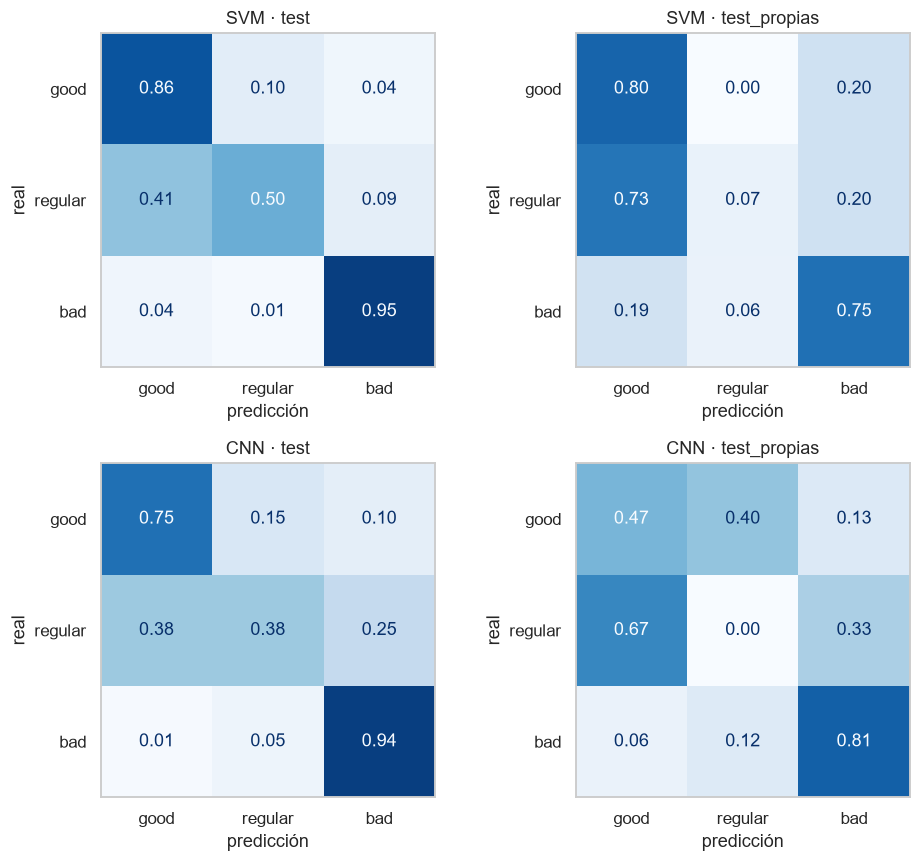

SVM        val           [[381, 41, 18], [9, 17, 6], [14, 12, 419]]  regular: 17/32 detectadas, 70 predichas
SVM        test          [[365, 44, 15], [13, 16, 3], [16, 6, 380]]  regular: 16/32 detectadas, 66 predichas
SVM        test_propias  [[12, 0, 3], [11, 1, 3], [3, 1, 12]]  regular: 1/15 detectadas, 2 predichas
CNN        val           [[317, 84, 39], [5, 20, 7], [11, 37, 397]]  regular: 20/32 detectadas, 141 predichas
CNN        test          [[318, 65, 41], [12, 12, 8], [4, 19, 379]]  regular: 12/32 detectadas, 96 predichas
CNN        test_propias  [[7, 6, 2], [10, 0, 5], [1, 2, 13]]  regular: 0/15 detectadas, 8 predichas
CNN (s43)  val           [[317, 88, 35], [0, 25, 7], [10, 36, 399]]  regular: 25/32 detectadas, 149 predichas
CNN (s43)  test          [[318, 67, 39], [11, 14, 7], [5, 9, 388]]  regular: 14/32 detectadas, 90 predichas
CNN (s43)  test_propias  [[7, 6, 2], [8, 1, 6], [3, 1, 12]]  regular: 1/15 detectadas, 8 predichas


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for i, n in enumerate(("SVM", "CNN")):
    for j, s in enumerate(("test", "test_propias")):
        ax = axes[i, j]
        ConfusionMatrixDisplay(confusion_matrix(Y[s], pred[n][s], normalize="true"), display_labels=QUALITY_CLASSES).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format=".2f", im_kw={"vmin": 0, "vmax": 1})
        ax.grid(False); ax.set(title=f"{n} · {s}", xlabel="predicción", ylabel="real")
fig.tight_layout(); fig.savefig(FIG_DIR / "eval_confusion.svg"); plt.show()
for n in ("SVM", "CNN", "CNN (s43)"):
    for s in SP:
        c = confusion_matrix(Y[s], pred[n][s]); print(f"{n:10s} {s:13s} {c.tolist()}  regular: {c[1,1]}/{c[1].sum()} detectadas, {c[:,1].sum()} predichas")

In [10]:
# Costo de negocio: fruta mala que pasa como buena, y fruta buena que no se vende como buena
neg = pd.DataFrame([{"modelo": n, "split": s, "bad → good": np.mean(pred[n][s][Y[s] == 2] == 0),
                     "bad → good o regular": np.mean(pred[n][s][Y[s] == 2] != 2), "good → no good": np.mean(pred[n][s][Y[s] == 0] != 0)}
                    for n in ("SVM", "CNN") for s in ("test", "test_propias")]).round(3); neg

,modelo,split,bad → good,bad → good o regular,good → no good
0,SVM,test,0.040,0.055,0.139
1,SVM,test_propias,0.188,0.250,0.200
2,CNN,test,0.010,0.057,0.250
3,CNN,test_propias,0.062,0.188,0.533


**Lectura.**

- **El patrón de la CNN en `val` se mantiene solo a medias en `test`**. Las falsas alarmas siguen (84 de 96 predicciones *regular* son
  erróneas; precisión 0,125), pero el recall alto no: 12 de 32 (0,375), frente a 20 de 32 en `val`. Parte de aquel recall era
  optimismo de haber elegido época y configuración con `val`. La segunda semilla hace lo mismo (0,781 → 0,438).
- **En las fotos propias *regular* prácticamente desaparece**: el SVM acierta 1 de 15 y la CNN 0 de 15. El SVM las manda sobre todo
  a *good* (11) y la CNN a *good* (10) y *bad* (5).
- **Costo de negocio, con signo contrario entre modelos**: en `test` la CNN deja pasar menos fruta mala como buena (1,0 % frente a 4,0 %),
  a cambio de rechazar más fruta buena (25,0 % frente a 13,9 %). En propias: 1 de 16 frente a 3 de 16, y 8 de 15 frente a 3 de 15.
  La CNN es más conservadora; con 16 fotos es solo un indicio.

## 5. Experimento del atajo del fondo

**Hipótesis** (notebooks 02–04): en Kaggle el fondo delata la clase, así que la imagen completa rinde igual o mejor en `val`/`test`,
pero cae en `test_propias`, con fondos nuevos. Si es cierta, la ventaja `fruta − completa` debe ser ≤ 0 en Kaggle y > 0 en las
fotos propias. Se compara cada par con bootstrap pareado; cada red de imagen completa es **una sola corrida**.

In [11]:
PARES = [("SVM", "SVM completa"), ("CNN", "CNN completa"), ("CNN sin aumento", "CNN sin aumento completa")]
filas = []
for a, b in PARES:
    for s in SP:
        for nm, me in (("macro-F1", F1), ("macro-F1 equiprob.", F1EQ), ("recall regular", REC)):
            dd = bootstrap_diferencia(Y[s], pred[a][s], pred[b][s], me, None if s == "test_propias" else D[s].grupo)
            ia, ib = intervalo_bootstrap(Y[s], pred[a][s], me), intervalo_bootstrap(Y[s], pred[b][s], me)
            filas.append({"modelo": a, "split": s, "métrica": nm, "fruta": me(Y[s], pred[a][s]), "fruta IC inf": ia[0], "fruta IC sup": ia[1],
                          "completa": me(Y[s], pred[b][s]), "completa IC inf": ib[0], "completa IC sup": ib[1],
                          "fruta − completa": dd[0], "dif IC inf": dd[1], "dif IC sup": dd[2]})
atajo = pd.DataFrame(filas)
atajo.round(4).to_csv(RESULTS_DIR / "atajo_test_propias.csv", index=False)
atajo[atajo["métrica"] != "recall regular"].set_index(["métrica", "modelo", "split"]).round(3)

,,,fruta,fruta IC inf,fruta IC sup,completa,completa IC inf,completa IC sup,fruta − completa,dif IC inf,dif IC sup
métrica,modelo,split,,,,,,,,,
macro-F1,SVM,val,0.727,0.684,0.767,0.731,0.686,0.774,-0.004,-0.047,0.035
macro-F1 equiprob.,SVM,val,0.769,0.695,0.832,0.762,0.683,0.830,0.007,-0.070,0.063
macro-F1,SVM,test,0.723,0.677,0.767,0.716,0.676,0.752,0.007,-0.050,0.054
macro-F1 equiprob.,SVM,test,0.758,0.674,0.823,0.791,0.720,0.847,-0.033,-0.095,0.034
macro-F1,SVM,test_propias,0.470,0.343,0.582,0.448,0.324,0.583,0.021,-0.097,0.140
macro-F1 equiprob.,SVM,test_propias,0.468,0.353,0.580,0.446,0.339,0.567,0.022,-0.103,0.138
macro-F1,CNN,val,0.649,0.615,0.680,0.679,0.641,0.716,-0.030,-0.064,0.007
macro-F1 equiprob.,CNN,val,0.742,0.679,0.799,0.747,0.677,0.811,-0.005,-0.063,0.081
macro-F1,CNN,test,0.647,0.611,0.681,0.645,0.614,0.680,0.002,-0.031,0.036


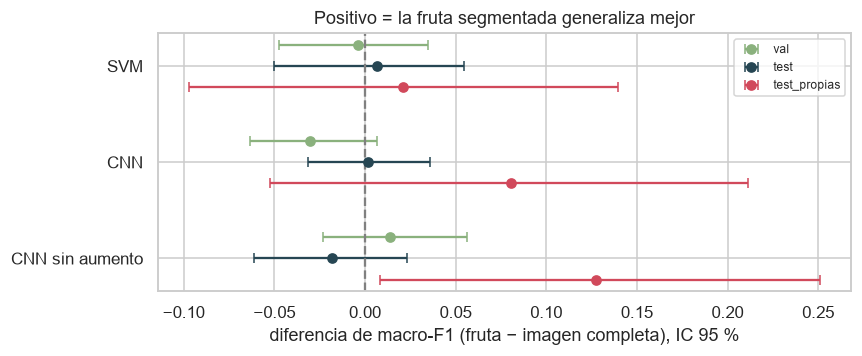

,good,regular,bad
SVM,26,2,18
SVM completa,23,2,21
CNN,18,8,20
CNN completa,15,15,16
CNN sin aumento,25,12,9
CNN sin aumento completa,22,2,22
REAL,15,15,16


In [12]:
q = atajo[atajo["métrica"] == "macro-F1"]
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, (s, col) in enumerate(zip(SP, ("#8ab17d", "#264653", "#d1495b"))):
    z = q[q.split == s].reset_index(drop=True); yy = np.arange(3) + (i - 1) * .22
    ax.errorbar(z["fruta − completa"], yy, xerr=[z["fruta − completa"] - z["dif IC inf"], z["dif IC sup"] - z["fruta − completa"]], fmt="o", color=col, capsize=3, label=s)
ax.axvline(0, color="gray", ls="--"); ax.set_yticks(range(3), [p[0] for p in PARES]); ax.invert_yaxis()
ax.set(xlabel="diferencia de macro-F1 (fruta − imagen completa), IC 95 %", title="Positivo = la fruta segmentada generaliza mejor")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG_DIR / "eval_atajo.svg"); plt.show()
# ¿Qué predice cada modelo en las fotos propias?
pd.DataFrame({n: pd.Series(pred[n]["test_propias"]).value_counts().reindex(range(3), fill_value=0).values for n in sum(PARES, ())} | {"REAL": np.bincount(Y["test_propias"])}, index=QUALITY_CLASSES).T

**Lectura: la hipótesis se confirma solo en parte.**

| | Kaggle (`val`/`test`) | Fotos propias: fruta − completa | ¿Apoya la hipótesis? |
|---|---|---|---|
| SVM | ≈ 0 | +0,021 [−0,097, 0,140] | No hay evidencia |
| CNN principal | ≈ 0 (−0,030 en `val`) | +0,081 [−0,052, 0,211] | A favor, pero no concluyente |
| CNN sin aumento | ≈ 0 | +0,127 [0,009, 0,251] | A favor; el intervalo excluye 0 por poco |

- En Kaggle la diferencia es pequeña y todos los intervalos incluyen 0: la imagen completa **no rinde claramente peor ni mejor**, y la primera mitad de la hipótesis se sostiene.
- En las fotos propias la fruta segmentada gana en los **tres** pares, pero la diferencia solo es distinguible de 0 en uno de los tres
  (y al hacer tres comparaciones, un intervalo que apenas excluye 0 pesa menos). Además hay **una sola corrida** por red completa.
- El efecto parece **mayor en la CNN que en el SVM**. Es coherente con que una CNN pueda aprender texturas y posición del fondo, mientras
  que las 80 características del SVM solo resumen color y textura; pero esto no se ha probado.
- **La comparación tampoco es limpia**: la máscara de las fotos propias incluye fondo o sombra en 39 de 46 (sección 7), de modo que
  la versión "fruta" también ve fondo. Eso puede haber reducido la diferencia.
- **El fondo no explica la caída por sí solo**: aun segmentando, el SVM pierde 0,29 entre Kaggle y las fotos propias.

## 6. ¿Sirvió el aumento de datos en las fotos propias?

`filtros_x2` (con aumento) se eligió frente a `sin_aumento` (mayor macro-F1 en `val`) pensando en las fotos propias. Matiz: ambas
difieren **también en el tamaño de la red** (32-64-128 frente a 16-32-64), así que la comparación no aísla el aumento. Es solo
análisis: la elección no cambia.

In [13]:
filas = []
for n in ("CNN", "CNN (s43)", "CNN sin aumento", "CNN sin aumento (s43)"):
    for s in SP:
        r = resumen(Y[s], pred[n][s]); lo, hi = intervalo_bootstrap(Y[s], pred[n][s], F1)
        filas.append({"modelo": n, "split": s, "macro-F1": r["macro-F1"], "IC inf": lo, "IC sup": hi, "equiprob.": F1EQ(Y[s], pred[n][s]), "recall regular": r["recall regular"], "recall bad": r["recall bad"], "recall good": r["recall good"]})
display(pd.DataFrame(filas).set_index(["modelo", "split"]).round(3))
for s in ("test", "test_propias"):
    for a, b in (("CNN", "CNN sin aumento"), ("CNN (s43)", "CNN sin aumento (s43)")):
        print(f"{s:13s} {a} − {b}: macro-F1 " + "{:+.3f} [{:+.3f}, {:+.3f}]".format(*bootstrap_diferencia(Y[s], pred[a][s], pred[b][s], F1, D[s].grupo)))

macro-F1  IC inf  IC sup  equiprob.  recall regular  recall bad  recall good
modelo                split                                                                                     
CNN                   val              0.649   0.615   0.680      0.742           0.625       0.892        0.720
                      test             0.647   0.611   0.681      0.667           0.375       0.943        0.750
                      test_propias     0.382   0.285   0.468      0.379           0.000       0.812        0.467
CNN (s43)             val              0.668   0.632   0.702      0.800           0.781       0.897        0.720
                      test             0.666   0.627   0.703      0.700           0.438       0.965        0.750
                      test_propias     0.393   0.270   0.499      0.390           0.067       0.750        0.467
CNN sin aumento       val              0.656   0.621   0.690      0.698           0.438       0.883        0.809
                      test             0.667   0.633   0.704      0.713           0.469       0.876        0.823
                      test_propias     0.411   0.289   0.524      0.411           0.067       0.438        0.800
CNN sin aumento (s43) val              0.654   0.616   0.688      0.723           0.531       0.876        0.775
                      test             0.690   0.652   0.726      0.765           0.594       0.913        0.804
                      test_propias     0.439   0.322   0.543      0.437           0.067       0.688        0.667

test          CNN − CNN sin aumento: macro-F1 -0.021 [-0.051, +0.013]


test          CNN (s43) − CNN sin aumento (s43): macro-F1 -0.025 [-0.076, +0.018]


test_propias  CNN − CNN sin aumento: macro-F1 -0.029 [-0.141, +0.086]


test_propias  CNN (s43) − CNN sin aumento (s43): macro-F1 -0.047 [-0.165, +0.079]


**Lectura: no se cumplió.** `sin_aumento` rinde igual o mejor que la CNN principal en los dos conjuntos: en propias 0,411 frente a
0,382 y, con la otra semilla, 0,439 frente a 0,393; en `test`, 0,667 y 0,690 frente a 0,647 y 0,666. Las cuatro diferencias van en
la misma dirección, **pero ningún intervalo excluye 0**: no hay evidencia de que el aumento ayudara, ni de que perjudicara.

- El motivo con que se eligió (fotos más oscuras y fruta más pequeña) era cierto en los datos (sección 7), pero el aumento no
  basta: no simula sombras dentro de la máscara, otros fondos ni un criterio de *regular* distinto.
- En propias, `sin_aumento` reparte los errores de otra forma: más recall de *good* (0,80) y menos de *bad* (0,44) que la CNN (0,47 y 0,81).
- La CNN principal sigue siendo `filtros_x2`, porque se fijó antes de mirar `test`. En `val` ya se advirtió que la diferencia con
  `sin_aumento` no era concluyente.

## 7. Brecha de dominio: Kaggle (`test`) frente a fotos propias

Se usa el macro-F1 equiprobable, que elimina el cambio de proporción de clases, y los recalls por clase. Después se
miden posibles causas.

In [14]:
rng = np.random.default_rng(42); filas = []
for n in ("SVM", "CNN", "CNN (s43)", "CNN sin aumento", "SVM completa", "CNN completa"):
    a, b = F1EQ(Y["test"], pred[n]["test"]), F1EQ(Y["test_propias"], pred[n]["test_propias"]); dd = []
    for _ in range(1000):
        i, j = rng.integers(0, len(Y["test"]), len(Y["test"])), rng.integers(0, 46, 46)
        dd.append(F1EQ(Y["test_propias"][j], pred[n]["test_propias"][j]) - F1EQ(Y["test"][i], pred[n]["test"][i]))
    rt, rp = resumen(Y["test"], pred[n]["test"]), resumen(Y["test_propias"], pred[n]["test_propias"])
    filas.append({"modelo": n, "F1 crudo test": rt["macro-F1"], "F1 crudo propias": rp["macro-F1"], "F1eq test": a, "F1eq propias": b, "brecha": b - a, "IC inf": np.percentile(dd, 2.5), "IC sup": np.percentile(dd, 97.5)}
                 | {f"Δrecall {c}": rp[f"recall {c}"] - rt[f"recall {c}"] for c in QUALITY_CLASSES})
brecha = pd.DataFrame(filas).set_index("modelo").round(3); brecha

,F1 crudo test,F1 crudo propias,F1eq test,F1eq propias,brecha,IC inf,IC sup,Δrecall good,Δrecall regular,Δrecall bad
modelo,,,,,,,,,,
SVM,0.723,0.470,0.758,0.468,-0.291,-0.427,-0.157,-0.061,-0.433,-0.195
CNN,0.647,0.382,0.667,0.379,-0.288,-0.396,-0.180,-0.283,-0.375,-0.130
CNN (s43),0.666,0.393,0.700,0.390,-0.310,-0.441,-0.179,-0.283,-0.371,-0.215
CNN sin aumento,0.667,0.411,0.713,0.411,-0.302,-0.433,-0.177,-0.023,-0.402,-0.438
SVM completa,0.716,0.448,0.791,0.446,-0.345,-0.479,-0.208,-0.146,-0.558,-0.131
CNN completa,0.645,0.301,0.687,0.300,-0.387,-0.538,-0.241,-0.490,-0.238,-0.468


In [15]:
fp = pd.read_csv(DATA_DIR / "features_fruta.csv").set_index("filename")
def covar(d):
    f = fp.loc[d.filename]; gris = [np.asarray(cargar_imagen(r).convert("L"), np.float32).mean() for _, r in d.iterrows()]
    return pd.DataFrame({"L* mediana de la fruta": f.lab_L_p50.values, "saturación mediana": f.hsv_S_p50.values, "brillo medio de la imagen": gris,
                         "área de la máscara": d.mask_area.values, "densidad de bordes": f.bordes_densidad.values, "solidez de la máscara": f.forma_solidez.values})
cv = {s: covar(D[s]) for s in ("test", "test_propias")}
t = pd.DataFrame({s: cv[s].median() for s in cv})
t["dif. estandarizada"] = (cv["test_propias"].mean() - cv["test"].mean()) / cv["test"].std()
display(t.round(2))
z = {s: np.abs(svm.named_steps["escala"].transform(cargar_X("fruta", D[s]))) for s in ("test", "test_propias")}
print("SVM: fracción de características a > 3 desv. de train:", {s: round(float((z[s] > 3).mean()), 4) for s in z})
seg = pd.read_csv(RESULTS_DIR / "segmentacion_propias_manual.csv").set_index("filename").segmentacion
dp = D["test_propias"].copy(); dp["seg"] = seg.loc[dp.filename].values
dp["SVM"] = pred["SVM"]["test_propias"] == Y["test_propias"]; dp["CNN"] = pred["CNN"]["test_propias"] == Y["test_propias"]
def barras(f):
    a = np.array(cargar_imagen(f)).astype(int); return (a[:, 2:8].std(0).max() < 4) or (a[2:8].std(1).max() < 4)
print("Fracción de fotos con barras de relleno:", {s: round(float(np.mean([barras(f) for _, f in D[s].iterrows()])), 2) for s in ("test", "test_propias")})
print("\nSegmentación (revisión visual hecha ANTES de ver predicciones): aciertos por categoría")
display(dp.groupby("seg")[["SVM", "CNN"]].agg(["sum", "count"]))
display(dp.groupby(["quality", "seg"])[["SVM", "CNN"]].agg(["sum", "count"]))
display(dp.groupby("fruit")[["SVM", "CNN"]].agg(["sum", "count"]))

,test,test_propias,dif. estandarizada
L* mediana de la fruta,56.35,53.01,-0.08
saturación mediana,0.61,0.67,0.23
brillo medio de la imagen,161.98,128.83,-0.93
área de la máscara,0.23,0.13,-1.00
densidad de bordes,0.14,0.14,0.20
solidez de la máscara,0.94,0.92,-0.18


SVM: fracción de características a > 3 desv. de train: {'test': 0.0091, 'test_propias': 0.0209}


Fracción de fotos con barras de relleno: {'test': 0.31, 'test_propias': 1.0}

Segmentación (revisión visual hecha ANTES de ver predicciones): aciertos por categoría


SVM       CNN      
       sum count sum count
seg                       
fondo    6    10   8    10
limpia   5     7   3     7
sombra  14    29   9    29

SVM       CNN      
               sum count sum count
quality seg                       
bad     fondo    6     8   7     8
        limpia   0     1   0     1
        sombra   6     7   6     7
good    fondo    0     1   1     1
        limpia   4     4   3     4
        sombra   8    10   3    10
regular fondo    0     1   0     1
        limpia   1     2   0     2
        sombra   0    12   0    12

SVM       CNN      
       sum count sum count
fruit                     
apple    8    17   4    17
banana  10    15   9    15
orange   7    14   7    14

**Lectura.** La caída es de ~0,29–0,31 de macro-F1 equiprobable en el SVM y las CNN segmentadas, y mayor con imagen completa
(−0,35 y −0,39). Todos los intervalos excluyen 0: **la brecha de dominio es real y grande**, mayor que la diferencia entre modelos.
Donde más cae es en *regular* (recall −0,43 en el SVM). Evidencia sobre las causas:

| Causa | Evidencia | Valoración |
|---|---|---|
| **Segmentación** | Revisión ciega: solo 7 de 46 máscaras limpias; 29 incluyen sombra y 10 un trozo de pared o piso. El 100 % de las fotos propias lleva barras de relleno (31 % en `test`), y GrabCut toma el color del borde (la barra) como fondo: el fondo real "parece fruta" | Problema claro; **no probamos cuánto explica de la caída** |
| **Tamaño de la fruta** | Área mediana de la máscara 0,13 frente a 0,23 (−1 desviación) | Claro; afecta sobre todo a la CNN (entrada 128×128) |
| **Iluminación** | Imagen más oscura (129 frente a 162), pero el L* de la fruta casi igual (53 frente a 56) | Menor en la fruta; mayor en sombras |
| **Criterio de *regular*** | En `train`, de 512 naranjas verdes 478 son *good* y 4 *regular*; las nuestras verdes son *regular* (sección 8) | Claro: parte de los "errores" son un **conflicto de etiquetas** |
| **Fuera de rango** | El 2,1 % de las características está a más de 3 desviaciones de train (0,9 % en `test`) | Leve |

**La segmentación no explica los errores por sí sola.** Entre las fotos con fondo en la máscara ambos modelos aciertan **más** (6 y 8 de 10)
que entre las que tienen sombra (14 y 9 de 29), porque 8 de esas 10 son *bad*: categoría y clase están confundidas y los
grupos son de 7–10 fotos. Es más informativo que las *regular* fallen casi todas, tengan la máscara que tengan (1 acierto de 15).

## 8. Análisis de errores

propias: fallan ambos 17, solo SVM 4, solo CNN 9, ninguno 16
test   : fallan ambos 58, solo SVM 39, solo CNN 91, ninguno 670


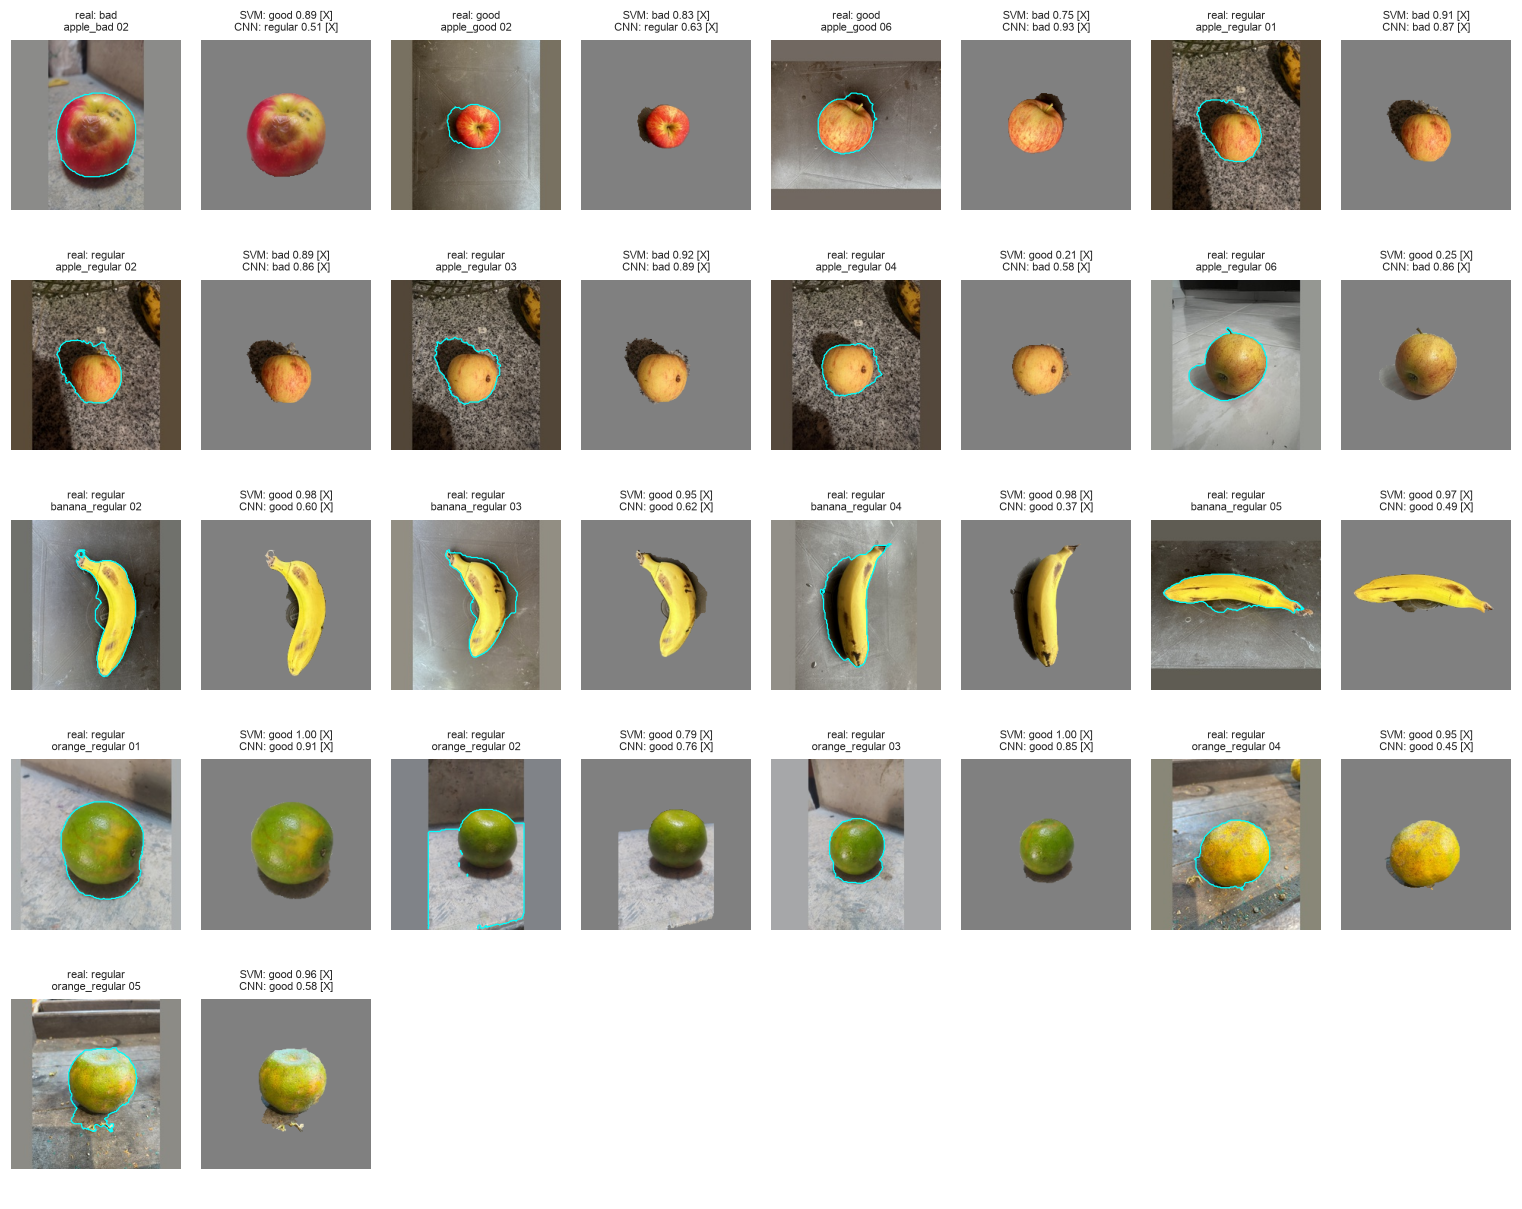

In [16]:
s = "test_propias"; y = Y[s]
conf = {n: prob[n][s][np.arange(len(y)), pred[n][s]] for n in ("SVM", "CNN")}
fS, fC = pred["SVM"][s] != y, pred["CNN"][s] != y
print(f"propias: fallan ambos {int((fS & fC).sum())}, solo SVM {int((fS & ~fC).sum())}, solo CNN {int((~fS & fC).sum())}, ninguno {int((~fS & ~fC).sum())}")
print("test   : fallan ambos {}, solo SVM {}, solo CNN {}, ninguno {}".format(*[int(v.sum()) for v in (
    (pred["SVM"]["test"] != Y["test"]) & (pred["CNN"]["test"] != Y["test"]), (pred["SVM"]["test"] != Y["test"]) & (pred["CNN"]["test"] == Y["test"]),
    (pred["SVM"]["test"] == Y["test"]) & (pred["CNN"]["test"] != Y["test"]), (pred["SVM"]["test"] == Y["test"]) & (pred["CNN"]["test"] == Y["test"]))]))
def cuadricula(d, idx, sp, archivo, ncol=4):
    nf_ = int(np.ceil(len(idx) / ncol)); fig, ax = plt.subplots(nf_, 2 * ncol, figsize=(3.5 * ncol, 2.25 * nf_), squeeze=False)
    for a in ax.flat: a.axis("off")
    ab = [c[0].upper() for c in QUALITY_CLASSES]
    for k, i in enumerate(idx):
        f = d.iloc[i]; rgb, m = np.array(cargar_imagen(f)), cargar_mascara(f); p, q = ax[k // ncol, 2 * (k % ncol)], ax[k // ncol, 2 * (k % ncol) + 1]
        p.imshow(rgb); p.contour(m, [.5], colors="cyan", linewidths=.8); q.imshow(aplicar_mascara(rgb, m))
        pr = lambda n: f"{QUALITY_CLASSES[pred[n][sp][i]]} {prob[n][sp][i, pred[n][sp][i]]:.2f}"
        p.set_title(f"real: {f.quality}\n{f.filename.rsplit('.', 1)[0].replace('_own_000', ' ').replace('_kaggle_', ' ')}", fontsize=7)
        q.set_title(f"SVM: {pr('SVM')} {'[X]' if pred['SVM'][sp][i] != f.y else ''}\nCNN: {pr('CNN')} {'[X]' if pred['CNN'][sp][i] != f.y else ''}", fontsize=7)
    fig.tight_layout(); fig.savefig(FIG_DIR / archivo, dpi=110); plt.show()
cuadricula(D[s], np.where(fS & fC)[0], s, "eval_errores_propias_ambos.png")

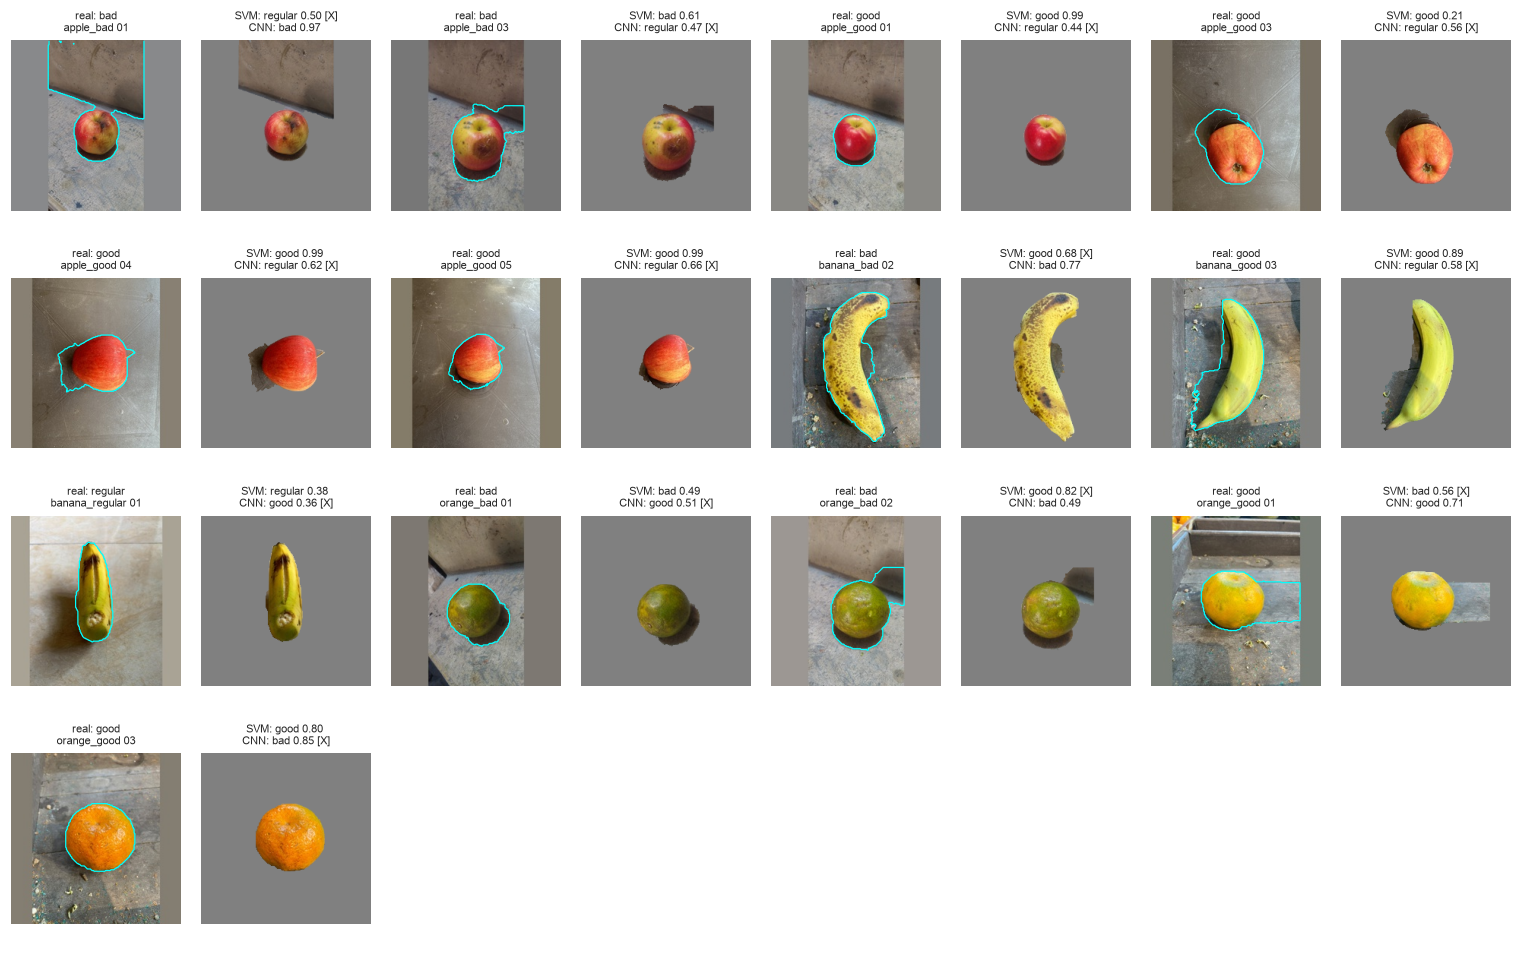

In [17]:
cuadricula(D[s], np.where(fS ^ fC)[0], s, "eval_errores_propias_uno.png")

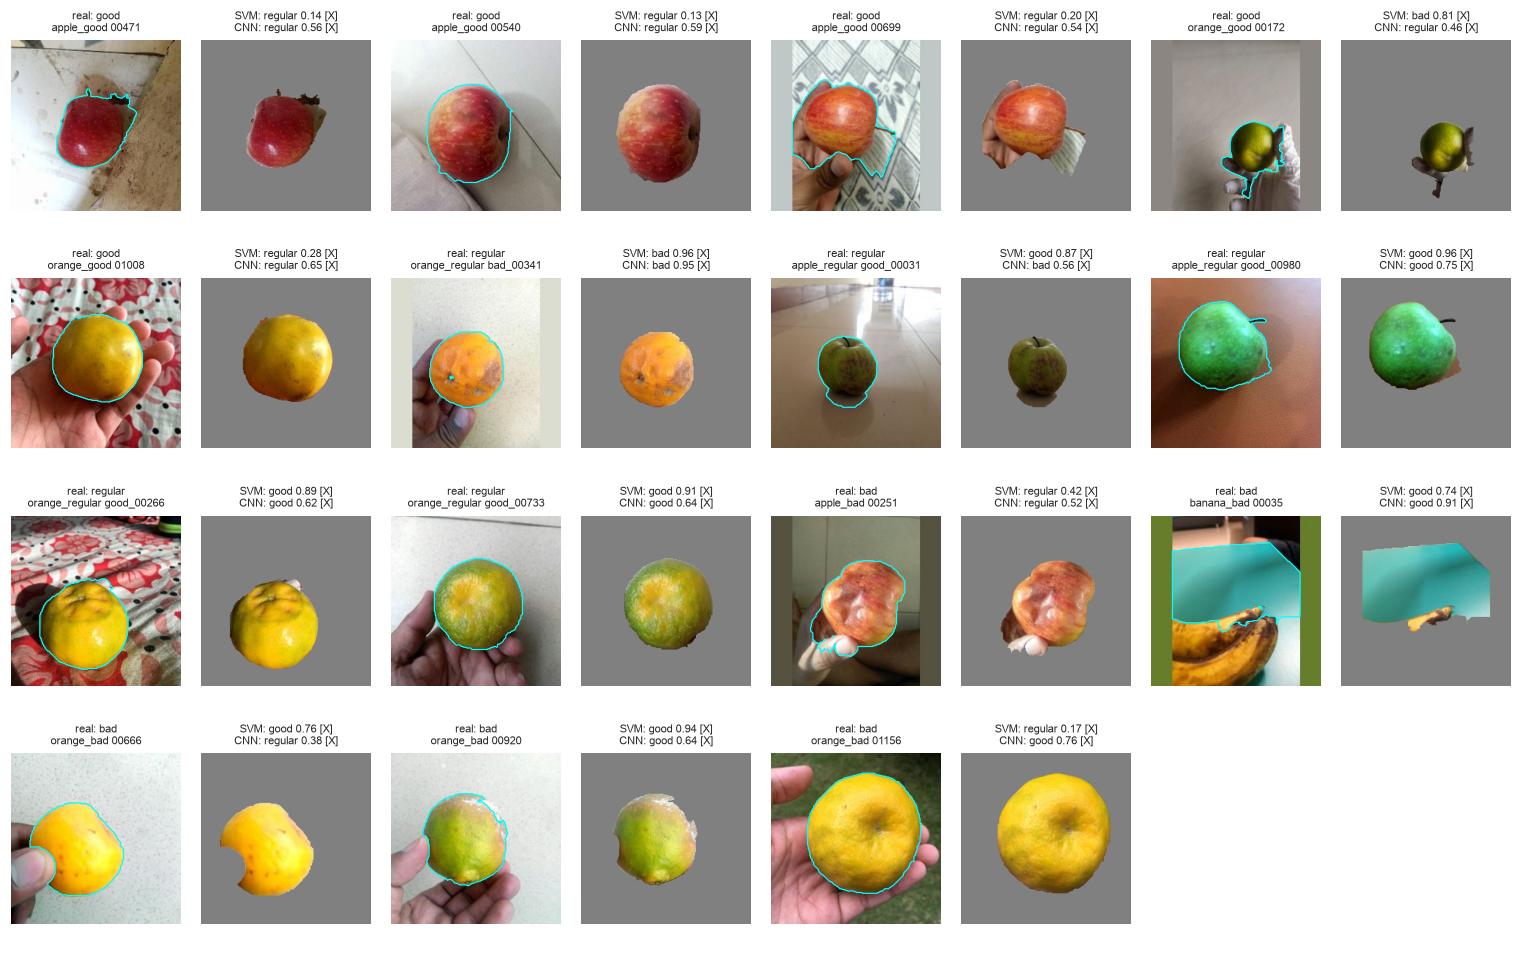

In [18]:
# test: errores de ambos modelos, muestra aleatoria fija por clase real (hasta 5 por clase)
e = np.where((pred["SVM"]["test"] != Y["test"]) & (pred["CNN"]["test"] != Y["test"]))[0]; rng = np.random.default_rng(42)
idx = np.concatenate([np.sort(rng.permutation(e[Y["test"][e] == k])[:5]) for k in range(3)])
cuadricula(D["test"], idx, "test", "eval_errores_test.png")

In [19]:
# Tipo de error, por modelo y conjunto
tipo = pd.DataFrame({(n, sp): pd.Series([f"{QUALITY_CLASSES[a]} → {QUALITY_CLASSES[b]}" for a, b in zip(Y[sp], pred[n][sp]) if a != b]).value_counts()
                     for n in ("SVM", "CNN") for sp in ("test", "test_propias")}).fillna(0).astype(int); display(tipo)
# Confianza: acierto y confianza media (SVM: probabilidad de Platt de la clase que da predict)
for n in ("SVM", "CNN"):
    for sp in ("test", "test_propias"):
        c = prob[n][sp][np.arange(len(Y[sp])), pred[n][sp]]; o = pred[n][sp] == Y[sp]
        print(f"{n} {sp:13s} acierto {o.mean():.3f} | confianza media {c.mean():.3f} (aciertos {c[o].mean():.3f}, errores {c[~o].mean():.3f}) | argmax≠predict: {(prob[n][sp].argmax(1) != pred[n][sp]).mean():.1%}")
ar = RESULTS_DIR / "errores_propias_causas.csv"
if ar.exists():
    cau = pd.read_csv(ar); x = cau.merge(dp[["filename", "seg", "SVM", "CNN"]], on="filename", suffixes=("", "_ok"))
    assert set(cau.filename) == set(dp.filename[fS | fC])
    display(x.groupby("causa").agg(fotos=("filename", "size"), falla_SVM=("SVM", lambda v: (~v).sum()), falla_CNN=("CNN", lambda v: (~v).sum()), ambos=("filename", lambda f: int(((~x.loc[f.index, "SVM"]) & (~x.loc[f.index, "CNN"])).sum()))).sort_values("fotos", ascending=False))

SVM               CNN             
               test test_propias test test_propias
bad → good       16            3    4            1
bad → regular     6            1   19            2
good → bad       15            3   41            2
good → regular   44            0   65            6
regular → bad     3            3    8            5
regular → good   13           11   12           10

SVM test          acierto 0.887 | confianza media 0.890 (aciertos 0.938, errores 0.517) | argmax≠predict: 7.7%
SVM test_propias  acierto 0.543 | confianza media 0.816 (aciertos 0.831, errores 0.799) | argmax≠predict: 8.7%
CNN test          acierto 0.826 | confianza media 0.828 (aciertos 0.873, errores 0.616) | argmax≠predict: 0.0%
CNN test_propias  acierto 0.435 | confianza media 0.718 (aciertos 0.812, errores 0.646) | argmax≠predict: 0.0%


,fotos,falla_SVM,falla_CNN,ambos
causa,,,,
sombra en la máscara,9,5,9,5
defecto localizado no detectado,6,6,5,5
frontera difusa (defecto sutil),4,3,4,3
fondo en la máscara,4,3,1,0
criterio: fruta verde,3,3,3,3
sin causa visible,2,0,2,0
reflejo o brillo,1,1,1,1
punto de vista atípico,1,0,1,0


In [20]:
# ¿Coincide el criterio de "verde" con Kaggle? Verde: a* mediano de la fruta < -5
todo = pd.concat([tr, D["test_propias"]]); todo["a"] = fp.loc[todo.filename].lab_a_p50.values
g = todo[todo.a < -5]; display(pd.crosstab([g.fruit, g.source], g.quality).reindex(columns=QUALITY_CLASSES, fill_value=0))

quality        good  regular  bad
fruit  source                    
apple  kaggle   334        8   18
banana kaggle   182       12   17
       own        4        1    0
orange kaggle   478        4   30
       own        2        3    0

**Lectura.**

- **Fallan ambos modelos en 17 de 46 fotos** (14 son *regular*). Solo el SVM falla en 4 y solo la CNN en 9.
- **Tipo de error**: en propias, 14 de los 21 fallos del SVM y 15 de los 26 de la CNN son *regular* mal clasificadas.
  *regular* se confunde más con *good* (11 y 10) que con *bad* (3 y 5).
- **Por causa** (lectura visual nuestra, hecha **después** de ver los errores, una causa principal por foto; es orientativa):
  el grupo mayor es la **sombra dentro de la máscara** (sobre todo manzanas: la sombra oscura podría
  parecer podredumbre; tres *regular* pasan a *bad*; falla la CNN en las 9 y el SVM en 5). Después, **defectos localizados no detectados** (manchas de los bananos *regular*, la mancha de `apple_bad 02`):
  los histogramas de color y el promedio global de la CNN diluyen manchas pequeñas.
- **Criterio de madurez**: naranjas verdes que etiquetamos *regular* y los modelos dan como *good* con confianza de 0,76 a 1,00. No es un
  capricho: en `train` el 93 % de las naranjas verdes es *good*. Nuestras etiquetas además son **incoherentes entre sí**: tres bananos
  muy verdes (`banana_good 01–03`) son *good*, aunque nuestro criterio dice que "muy verde" es *regular*.
- **Reflejos**: la mancha blanca de `orange_regular 05`. **Fondo en la máscara**: 4 fotos de error.
- **En `test`**: los errores compartidos incluyen manos dentro de la máscara, segmentaciones fallidas (`banana_bad 00035`: la máscara es
  una carpeta) y *regular* de aspecto muy parecido a *good*: la frontera es difusa también para una persona.
- **La confianza no avisa en las fotos propias**: el SVM está tan seguro cuando falla (0,80) como cuando acierta (0,83), mientras que en
  `test` sí distinguía (0,52 frente a 0,94). En la app, mostrar la probabilidad **no** protege de los errores por cambio de dominio.

## 9. Tamaño

`tamano` son los terciles por fruta de `d_eq` (diámetro equivalente de la máscara), con cortes de `train`. **No hay etiqueta manual
de tamaño**, así que no se puede calcular un acierto: se revisa si la medida se comporta como debería.

seg,fondo,limpia,sombra,All
tam,,,,
pequeno,5,7,26,38
mediano,1,0,3,4
grande,4,0,0,4
All,10,7,29,46


tam,pequeno,mediano,grande
fruit,,,
apple,15,0,2
banana,12,3,0
orange,11,1,2


cortes d_eq (train): {'apple': array([0.492, 0.573]), 'banana': array([0.506, 0.628]), 'orange': array([0.502, 0.59 ])}
d_eq mediana: {'test': {'apple': 0.545, 'banana': 0.578, 'orange': 0.525}, 'test_propias': {'apple': 0.362, 'banana': 0.447, 'orange': 0.41}}


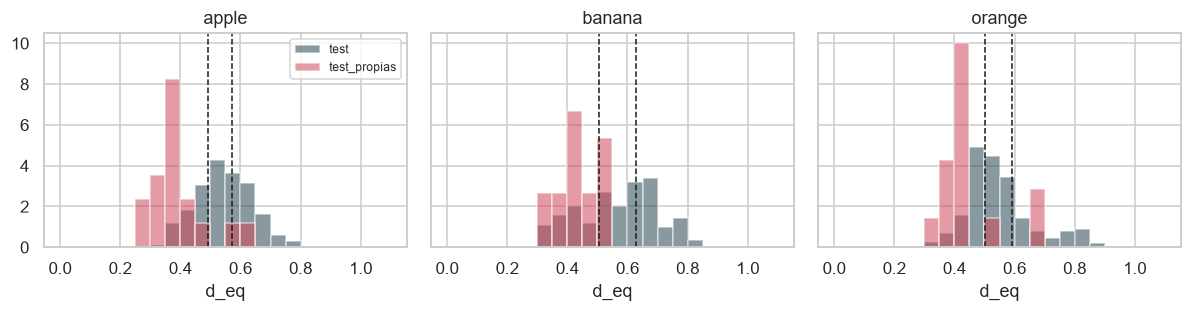

In [21]:
dp["tam"] = pd.Categorical(dp.tamano, SIZE_CLASSES)
display(pd.crosstab(dp.tam, dp.seg, margins=True)); display(pd.crosstab(dp.fruit, dp.tam))
tr_c = {f: np.percentile(g.d_eq, [100/3, 200/3]).round(3) for f, g in tr.groupby("fruit")}
print("cortes d_eq (train):", tr_c); print("d_eq mediana:", {s: D[s].groupby("fruit").d_eq.median().round(3).to_dict() for s in ("test", "test_propias")})
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, f in zip(axes, FRUITS):
    for s, col in (("test", "#264653"), ("test_propias", "#d1495b")):
        g = D[s][D[s].fruit == f].d_eq; ax.hist(g, bins=np.linspace(0, 1.1, 23), density=True, alpha=.55, color=col, label=s)
    for c in tr_c[f]: ax.axvline(c, color="k", ls="--", lw=1)
    ax.set(title=f, xlabel="d_eq")
axes[0].legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG_DIR / "eval_tamano.svg"); plt.show()

**Lectura.** Las fotos propias quedan casi todas "pequeño" (38 de 46) porque la fruta ocupa menos imagen, no porque sea pequeña:
`d_eq` mide la fruta **en la foto** y depende de la distancia. Además, **las 4 únicas "grande" son segmentaciones fallidas** (máscara con pared
o piso), es decir, el tamaño hereda los errores de la máscara. Con los cortes de Kaggle la etiqueta de tamaño **no es válida** en
fotos propias. No se puede medir el acierto, porque falta una etiqueta manual de tamaño (la pide el enunciado, §2.3). En la app hace falta
**distancia fija** (o un objeto de referencia) y **recalibrar los cortes** con ese montaje.

## 10. Costo de cada modelo

In [22]:
ims = [(np.array(cargar_imagen(f)), cargar_mascara(f)) for _, f in D["test"].iloc[:30].iterrows()]
def ms_(fn):
    fn(*ims[0]); t = []
    for a in ims:
        t0 = time.perf_counter(); fn(*a); t.append((time.perf_counter() - t0) * 1e3)
    return round(float(np.median(t)), 1)
costo = pd.DataFrame({"mediana (ms, CPU)": {"segmentación GrabCut (común)": ms_(lambda r, m: segmentar_fruta(r)), "SVM (características + predict + prob)": ms_(ms.predecir), "CNN": ms_(mc.predecir)},
              "tamaño (MB)": {"SVM (características + predict + prob)": (CHECKPOINTS_DIR / "ml_mejor.joblib").stat().st_size / 1e6, "CNN": (CHECKPOINTS_DIR / f"cnn_{PRINCIPAL}.pt").stat().st_size / 1e6}}); costo.round(2)

,"mediana (ms, CPU)",tamaño (MB)
segmentación GrabCut (común),136.7,NaN
SVM (características + predict + prob),18.2,0.92
CNN,4.8,0.42


## 11. Conclusiones

**Pregunta de negocio (fase 1):** ¿se puede reemplazar o apoyar la clasificación manual, lenta y subjetiva, con una foto?
**Respuesta: en condiciones parecidas a las de Kaggle, sí como apoyo para separar *good* y *bad*; con fotos propias, todavía no.**

1. **Generalizan dentro de Kaggle, no fuera.** SVM 0,723 y CNN 0,647 en `test` (igual que en `val`); 0,470 y 0,382 en fotos propias. Ningún
   modelo cumple las metas (0,85 y 0,70). La brecha (~0,29 equiprobable) es mayor que cualquier diferencia entre modelos.
2. **Modelo recomendado para la app: el SVM** (la elección ya hecha con `val`, que `test` respalda). Motivos: en `test` supera a la CNN
   principal (+0,076, IC por tomas [0,016, 0,134]); en propias tiene el mayor valor puntual, aunque sin diferencia demostrable; y su resultado apenas cambia
   con el fondo (fruta − completa ≈ 0, aunque con un intervalo ancho). En costo no hay diferencia práctica: la segmentación (~130 ms) domina frente a los ~15 ms del
   SVM y ~5 ms de la CNN. **A favor de la CNN**: deja pasar menos fruta mala como buena, si ese error fuera el más caro.
3. ***regular* no está resuelta**: 0,33 de F1 en `test` (SVM) y 1 de 15 en propias. Con 146 ejemplos de entrenamiento y un criterio que
   no coincide entre Kaggle y nuestras fotos, no es solo cuestión de modelo.
4. **El atajo del fondo**: hay indicios en la CNN y ninguno en el SVM; no es la causa principal de la caída.
5. **El aumento no se notó** en las fotos propias. La decisión era razonable, pero los datos no la respaldan.
6. **La calidad de los datos es el cuello de botella**: sombras y relleno que rompen la segmentación, etiquetas con criterio incoherente,
   y fondos, distancia y luz distintos. Es lo primero que mejoraría el sistema.

**Limitaciones.** (a) 46 fotos propias (45 tomas, varias de la misma fruta) y 15 *regular*: intervalos de ±0,12. (b) Solo 32 *regular* en
`test`. (c) Datos de entrenamiento casi todos de Kaggle, con *regular* construida a mano. (d) Una sola corrida por red de imagen
completa y dos semillas por CNN. (e) Las causas de error y la calidad de la segmentación las juzgó una sola persona/herramienta, sin
segundo revisor; las causas, además, después de ver los errores. (f) El tamaño depende de la distancia y no tiene etiqueta manual.
(g) `test` y `test_propias` ya se usaron: cualquier mejora futura necesita **fotos nuevas** para medirse con honestidad.

**Trabajo futuro.** (1) Unificar y documentar el criterio de *regular* (¿verde = *regular*?) y reetiquetar con dos personas (kappa). (2)
Corregir la segmentación: ignorar las barras de relleno al estimar el fondo y excluir sombras. (3) Más fotos propias en el montaje
de la app (fondo, luz y distancia fijos), una parte para entrenar y otra, nueva, para probar. (4) Características locales para manchas
(o atención en la CNN) y *transfer learning*. (5) Calibrar la confianza y rechazar fotos fuera de dominio. (6) Recalibrar el tamaño.